In [1]:
# 导入库
import pandas as pd                 # 表格处理
import plotly.express as px         # 画图（饼图等）
import dash                         # Dash：用纯 Python 写网页仪表盘
from dash import dcc                # dcc = Dash 的"核心组件"（图表 dcc.Graph、输入框 dcc.Input 等）
from dash import html               # html = 用 Python 写 HTML 标签（H1、P、Div 等）
from dash.dependencies import Input, Output   # 回调要用：Input=输入、Output=输出

# 读取"航空公司准点"数据（本地文件），并随机抽 500 行做演示
airline_data = pd.read_csv('Datasets/airline_data.csv',
                           encoding='ISO-8859-1',
                           dtype={'Div1Airport': str, 'Div1TailNum': str,
                                  'Div2Airport': str, 'Div2TailNum': str})

# random_state=42 → 每次抽样结果都一样，方便复现
data = airline_data.sample(n=500, random_state=42)

In [2]:
app = dash.Dash(__name__)

# 用 display:flex 让同一段里的两张图"横着并排"
app.layout = html.Div(children=[
    html.H1('Flight Delay Time Statistics',
            style={'textAlign': 'center', 'color': '#503D36', 'font-size': 30}),
    html.Div(["Input Year: ", dcc.Input(id='input-year', value='2010',
                                        type='number',
                                        style={'height': '35px', 'font-size': 30})],
             style={'font-size': 30}),
    html.Br(),
    html.Br(),
    # 第 1 段：承运方延误 + 天气延误
    html.Div([
        html.Div(dcc.Graph(id='carrier-plot')),
        html.Div(dcc.Graph(id='weather-plot'))
    ], style={'display': 'flex'}),
    # 第 2 段：国家空管延误 + 安检延误
    html.Div([
        html.Div(dcc.Graph(id='nas-plot')),
        html.Div(dcc.Graph(id='security-plot'))
    ], style={'display': 'flex'}),
    # 第 3 段：前序航班延误
    html.Div(dcc.Graph(id='late-plot'), style={'width': '65%'})
])
print('布局创建完成！')

布局创建完成！


In [3]:
def compute_info(airline_data, entered_year):
    """按年份筛选数据，算出 5 种延误各自的"每月 × 各航空公司"平均值。
    参数：airline_data = 原始数据；entered_year = 用户输入的年份
    返回：5 个算好的小表
    """
    df = airline_data[airline_data['Year'] == int(entered_year)]
    avg_car = df.groupby(['Month', 'Reporting_Airline'])['CarrierDelay'].mean().reset_index()
    avg_weather = df.groupby(['Month', 'Reporting_Airline'])['WeatherDelay'].mean().reset_index()
    avg_NAS = df.groupby(['Month', 'Reporting_Airline'])['NASDelay'].mean().reset_index()
    avg_sec = df.groupby(['Month', 'Reporting_Airline'])['SecurityDelay'].mean().reset_index()
    avg_late = df.groupby(['Month', 'Reporting_Airline'])['LateAircraftDelay'].mean().reset_index()
    return avg_car, avg_weather, avg_NAS, avg_sec, avg_late

In [4]:
# 多输出回调
@app.callback([
              Output(component_id='carrier-plot',  component_property='figure'),
              Output(component_id='weather-plot',  component_property='figure'),
              Output(component_id='nas-plot',      component_property='figure'),
              Output(component_id='security-plot', component_property='figure'),
              Output(component_id='late-plot',     component_property='figure')
              ],
              Input(component_id='input-year', component_property='value'))
def get_graph(entered_year):
    # 先算数据
    avg_car, avg_weather, avg_NAS, avg_sec, avg_late = compute_info(airline_data, entered_year)
    # 再分别画 5 张折线图；color='Reporting_Airline' 表示按航空公司分色
    carrier_fig = px.line(avg_car, x='Month', y='CarrierDelay', color='Reporting_Airline',
                          title='Average carrier delay time (minutes) by airline')
    weather_fig = px.line(avg_weather, x='Month', y='WeatherDelay', color='Reporting_Airline',
                          title='Average weather delay time (minutes) by airline')
    nas_fig = px.line(avg_NAS, x='Month', y='NASDelay', color='Reporting_Airline',
                      title='Average NAS delay time (minutes) by airline')
    sec_fig = px.line(avg_sec, x='Month', y='SecurityDelay', color='Reporting_Airline',
                      title='Average security delay time (minutes) by airline')
    late_fig = px.line(avg_late, x='Month', y='LateAircraftDelay', color='Reporting_Airline',
                       title='Average late aircraft delay time (minutes) by airline')
    return [carrier_fig, weather_fig, nas_fig, sec_fig, late_fig]

In [5]:
try:
    app.run(jupyter_mode='inline')
    print('Dash 应用已启动（notebook 内联模式）。')
except Exception as e:
    print('内联启动受限（不影响代码本身正确性）：', e)

内联启动受限（不影响代码本身正确性）： Address 'http://127.0.0.1:8050' already in use.
    Try passing a different port to run.


=== Carrier Delay（承运方延误） ===


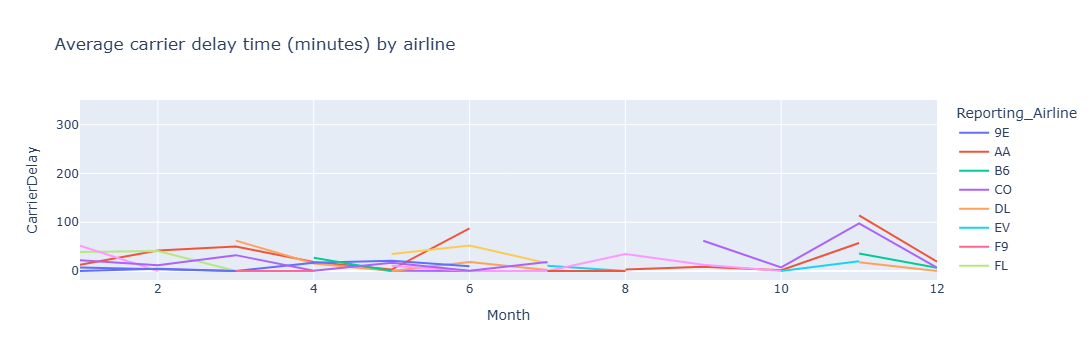

=== Weather Delay（天气延误） ===


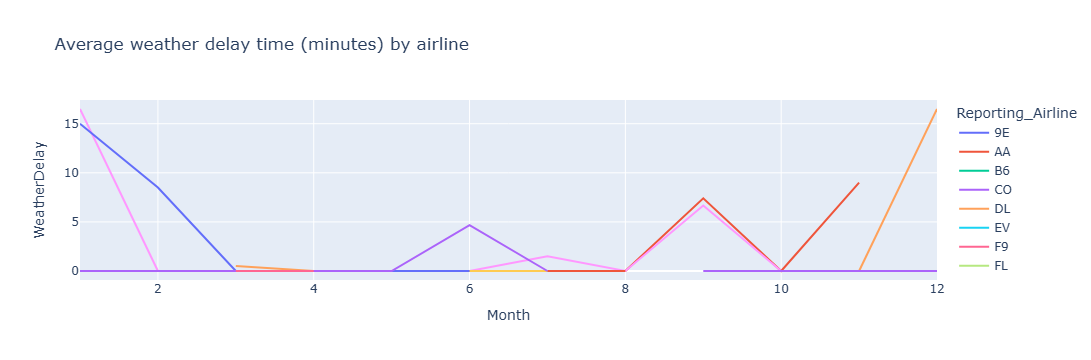

=== NAS Delay（国家空管延误） ===


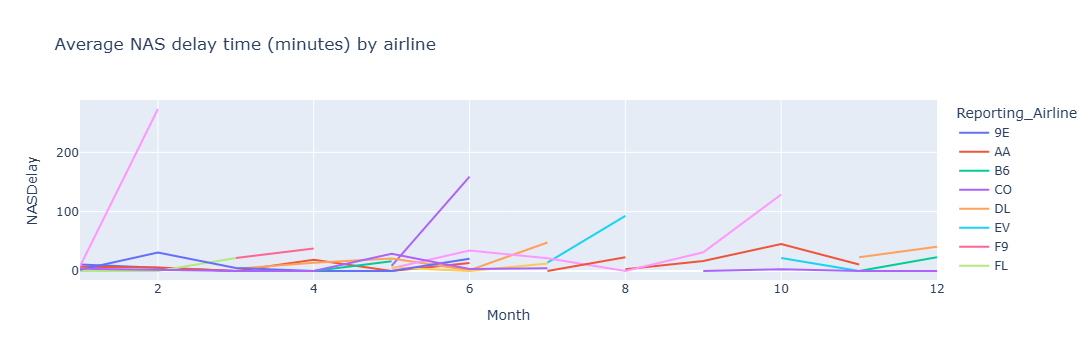

=== Security Delay（安检延误） ===


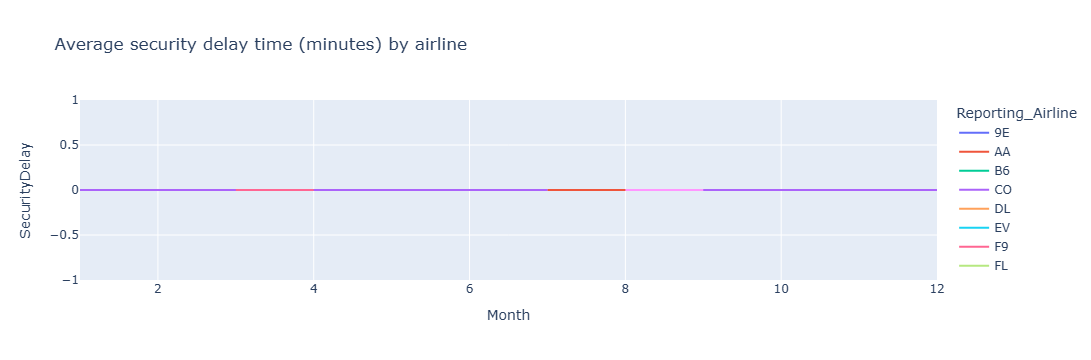

=== Late Aircraft Delay（前序航班延误） ===


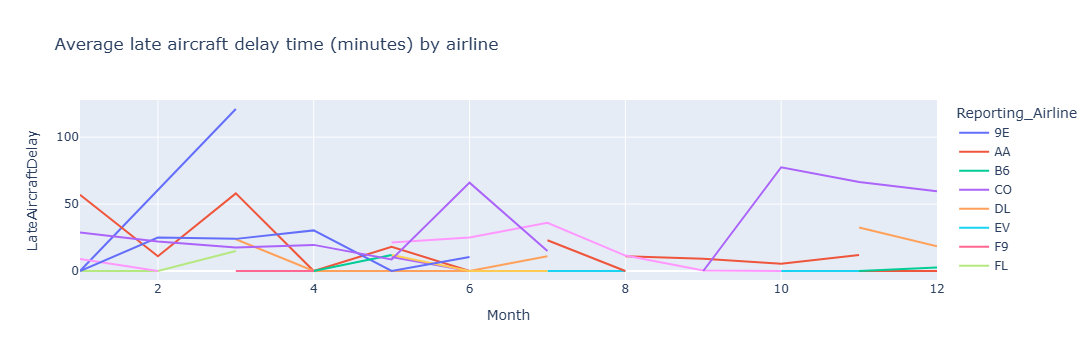

In [6]:
# 直接调用回调，拿到 5 张图，逐张显示
figs = get_graph('2010')
names = ['Carrier Delay（承运方延误）', 'Weather Delay（天气延误）',
         'NAS Delay（国家空管延误）', 'Security Delay（安检延误）',
         'Late Aircraft Delay（前序航班延误）']

for name, f in zip(names, figs):
    print('===', name, '===')
    f.show()

In [8]:
#  练习：只改标题文字与字号
from dash import html as _html

app.layout.children[0] = _html.H1(
    'Flight Details Statistics Dashboard',
    style={'textAlign': 'center', 'color': '#503D36', 'font-size': 35})

print('新标题：', app.layout.children[0].children)

新标题： Flight Details Statistics Dashboard
